# Portion 1 — Data audit & preprocessing (CPU)
**Project:** Self-supervised spatiotemporal learning of DNA-origami adsorption from HS-AFM
**Dataset:** Pothineni, Barner & Keller (2024), Zenodo [10.5281/zenodo.14275812](https://doi.org/10.5281/zenodo.14275812), CC-BY 4.0

What this notebook does, one zip file at a time:
1. Verify each zip (MD5 vs Zenodo), copy it to local disk, read every `.jpk` frame **directly from the zip** (no full extraction).
2. Parse the JPK TIFF header: calibrated height (m → nm), scan size, pixel size (nm/px), true timestamps.
3. Fixed preprocessing: plane levelling → scan-line alignment (median of differences) → slow line-drift removal → bare mica = 0 nm.
4. Per-frame QC: non-finite / saturated pixels, trace–retrace agreement, scan-line streaks, drift, SSIM, exact & frozen duplicates.
   *Hard* flags (`flag_*`) exclude a frame; *soft* flags (`warn_*`) are only reported. Drift is a warning only: in sparse frames the
   triangles themselves diffuse on mica, so a global shift mixes stage drift with real molecular motion.
5. Save float16 stacks per imaging session + `frames_all.csv`, `sessions.csv`.
6. Build split manifests (LOCO, high-concentration hold-out, early→late time split) and run a leakage audit.
7. Dataset figures (timeline, example frames, QC traces, preprocessing demo) and a PASS/FAIL gate table.

**Runtime:** CPU only. Expect roughly 2–5 min per zip on a standard Colab CPU runtime (mostly Drive I/O).
The notebook is **resumable**: a finished concentration is skipped unless `FORCE = True`.

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Install / import ---------------------------------------------------
import importlib, subprocess, sys
for pkg in ['tifffile', 'scikit-image']:
    mod = 'skimage' if pkg == 'scikit-image' else pkg
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

import os, io, re, json, glob, time, shutil, hashlib, zipfile, tempfile, warnings, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import tifffile
import skimage
from skimage.metrics import structural_similarity
from skimage.registration import phase_cross_correlation
from skimage.filters import gaussian
from scipy import ndimage as ndi
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
print('numpy', np.__version__, '| pandas', pd.__version__, '| tifffile', tifffile.__version__,
      '| skimage', skimage.__version__, '| matplotlib', matplotlib.__version__)

numpy 2.1.3 | pandas 2.2.3 | tifffile 2026.9.20 | skimage 0.25.2 | matplotlib 3.10.0


In [3]:
# ---- 2. Configuration (edit here only) ---------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
OUT_DIR  = os.path.join(DATA_DIR, 'portion1_outputs')

# One entry per zip. Missing zips are skipped automatically (e.g. if 12nM.zip is not uploaded yet).
ZIP_FILES = {
    '2nM':  '2nM.zip',
    '4nM':  '4nM.zip',
    '6nM':  '6nM.zip',
    '8nM':  '8nM.zip',
    '10nM': '10nM.zip',
    '12nM': '12nM.zip',
}
# Official MD5 checksums from the Zenodo record
ZENODO_MD5 = {
    '2nM.zip':  '85067e45aacfb7a35cfba8e2e0753399',
    '4nM.zip':  '5f6fc4524e74407d0dd7f6063dbc35f0',
    '6nM.zip':  '4430c2042613e3914b08825bccd3c73d',
    '8nM.zip':  'e0e4c651fdcb8941f9fd2e38511ffcad',
    '10nM.zip': 'e156960f1a0214db2e3213ae5725ce4f',
    '12nM.zip': '603cebe811f74911c7b7ea0777e7bea3',
    'overview4x4um.zip': '34adcf2d75988f14c38c65174908955b',
}
VERIFY_MD5     = True    # ~20-40 s per GB on Drive
COPY_TO_LOCAL  = True    # copy each zip to the Colab VM disk first (much faster random access than Drive)
SAVE_RETRACE   = True    # also store the retrace height channel (used in Portion 2 for repeatability)
FORCE          = False   # True = re-process concentrations that are already done

# Preprocessing (fixed, applied identically to every frame)
ROW_Q          = 15      # % lowest pixels per row used as the mica reference for scan-line alignment
FLATTEN_ITERS  = 3
# QC thresholds
SAT_FRAC_MAX   = 0.01    # >1 % pixels stuck at the raw min/max  -> flag
TR_CORR_MIN    = 0.30    # trace/retrace correlation below this  -> warn
STREAK_FACTOR  = 1.40    # line anisotropy > 1.4 x session median -> warn (unstable tip / scan-line streaks)
DRIFT_JUMP_NM  = 50.0    # frame-to-frame global shift above this -> warn (molecules also move, so warn only)
LOW_CONTRAST_NM = 1.3    # p99-p1 height range below this -> warn (compressed / lost imaging contrast)
FROZEN_EPS_NM  = 1e-4    # max |difference| to previous frame below this -> frozen/duplicate frame
# Splits
TEMPORAL_FRACS = (0.6, 0.2, 0.2)   # train / val / test fraction of each session (time-ordered)
TEMPORAL_GAP   = 16                # frames dropped between blocks (>= max model window length)
SEED = 0

LOCAL_TMP = '/content/p1_tmp' if os.path.isdir('/content') else os.path.join(tempfile.gettempdir(), 'p1_tmp')
for d in [OUT_DIR, os.path.join(OUT_DIR, 'processed'), os.path.join(OUT_DIR, 'figures'), LOCAL_TMP]:
    os.makedirs(d, exist_ok=True)

assert os.path.isdir(DATA_DIR), f'DATA_DIR not found: {DATA_DIR}  (is Drive mounted and the folder name exact?)'
print('DATA_DIR :', DATA_DIR)
print('OUT_DIR  :', OUT_DIR)
print('Files in DATA_DIR:', sorted(os.listdir(DATA_DIR)))

DATA_DIR : /content/drive/MyDrive/Koushik-experiment/
OUT_DIR  : /content/drive/MyDrive/Koushik-experiment/portion1_outputs
Files in DATA_DIR: ['10nM.zip', '2nM.zip', '4nM.zip', '6nM.zip', '8nM.zip', 'portion1_outputs']


In [4]:
# ---- 3. JPK reader (multi-page TIFF with JPK private tags) ------------------
# Page 0 = thumbnail + global header; pages 1.. = channels (height/amplitude/phase, trace & retrace).
# Every channel stores calibration "slots"; each slot has a LinearScaling multiplier/offset applied to the RAW int32.
TAG = dict(start=32771, end=32774, epoch_ms=32776, x0=32832, y0=32833, ulen=32834, vlen=32835,
           angle=32836, ilen=32838, jlen=32839, feedback=32816,
           ch_name=32848, ch_retrace=32849, n_slots=32896, default_slot=32897)
SLOT0, SLOT_STRIDE = 32912, 48       # slot k starts at 32912 + 48*k ; +18 unit, +19 scaling type, +20 mult, +21 offset

def _tags(page):
    return {t.code: t.value for t in page.tags.values()}

def _parse_time(p0, member_name):
    """Absolute acquisition time (UTC seconds). Priority: epoch-ms tag -> start string -> file name."""
    v = p0.get(TAG['epoch_ms'])
    try:
        return float(v) / 1000.0
    except (TypeError, ValueError):
        pass
    s = p0.get(TAG['start'])
    if isinstance(s, str):
        try:
            return datetime.strptime(s[:23], '%Y-%m-%d %H:%M:%S.%f').replace(tzinfo=timezone.utc).timestamp()
        except ValueError:
            pass
    m = re.search(r'(\d{4}\.\d{2}\.\d{2}-\d{2}\.\d{2}\.\d{2}\.\d{3})', member_name)
    if m:
        return datetime.strptime(m.group(1), '%Y.%m.%d-%H.%M.%S.%f').replace(tzinfo=timezone.utc).timestamp()
    return np.nan

def read_jpk_height(buf, member_name='', want_retrace=True):
    """Returns dict(trace=nm-free metres array, retrace=array|None, raw_trace=int array, meta=dict)."""
    out = {'trace': None, 'retrace': None, 'raw_trace': None}
    with tifffile.TiffFile(io.BytesIO(buf)) as tf:
        p0 = _tags(tf.pages[0])
        meta = {k: p0.get(TAG[k]) for k in ['ulen', 'vlen', 'ilen', 'jlen', 'angle', 'feedback', 'start']}
        meta['t_abs'] = _parse_time(p0, member_name)
        for pg in tf.pages[1:]:
            tg = _tags(pg)
            if tg.get(TAG['ch_name']) != 'height':
                continue
            is_ret = int(tg.get(TAG['ch_retrace'], 0)) == 1
            if is_ret and not want_retrace:
                continue
            raw = pg.asarray()
            mult, off, unit = None, 0.0, None
            default = tg.get(TAG['default_slot'])
            for k in range(int(tg.get(TAG['n_slots'], 0))):
                b = SLOT0 + SLOT_STRIDE * k
                if tg.get(b) == default and tg.get(b + 19) == 'LinearScaling':
                    mult, off, unit = float(tg[b + 20]), float(tg[b + 21]), tg.get(b + 18)
            if mult is None:
                raise ValueError(f'no linear calibration for height slot "{default}"')
            arr = raw.astype(np.float64) * mult + off
            if is_ret:
                out['retrace'] = arr
            else:
                out['trace'], out['raw_trace'] = arr, raw
                meta.update(height_slot=default, height_unit=unit)
    if out['trace'] is None:
        raise ValueError('height trace channel not found')
    out['meta'] = meta
    return out

In [5]:
# ---- 4. Preprocessing: plane + scan-line alignment, mica = 0 nm ---------------
def plane_level(h, mask=None):
    ny, nx = h.shape
    yy, xx = np.mgrid[:ny, :nx]
    m = np.ones(h.shape, bool) if mask is None else mask
    if m.sum() < 10:
        m = np.ones(h.shape, bool)
    A = np.c_[xx[m], yy[m], np.ones(m.sum())]
    c, *_ = np.linalg.lstsq(A, h[m], rcond=None)
    return h - (c[0] * xx + c[1] * yy + c[2])

def flatten_nm(h_m, q=ROW_Q, iters=FLATTEN_ITERS, nm_per_px=5.0):
    """metres -> flattened nm, bare mica ~ 0 nm.
    1) plane fit; 2) scan-line alignment by MEDIAN OF DIFFERENCES between neighbouring lines (Gwyddion-style; robust
       for both sparse frames and closed lattices); 3) plane re-fit on the lowest q% pixels; 4) removal of slow residual
       line drift (running median of each line's low level over ~200 nm); 5) zero = median of the lowest q% pixels."""
    h = plane_level(np.asarray(h_m, np.float64) * 1e9)
    d = np.median(np.diff(h, axis=0), axis=1)
    h = h - np.r_[0.0, np.cumsum(d)][:, None]
    for _ in range(iters):
        h = plane_level(h, mask=h <= np.percentile(h, q))
    lo = np.percentile(h, q, axis=1)
    win = max(5, int(round(200.0 / nm_per_px)) | 1)
    h = h - ndi.median_filter(lo, size=win, mode='nearest')[:, None]
    h = h - np.median(h[h <= np.percentile(h, q)])
    return h.astype(np.float32)

def line_anisotropy(h_nm):
    """Streak score: median |row-to-row step| / median |pixel-to-pixel step along the fast axis|.
    Clean frames ~1.2-2 (depends on content); streaky / unstable-tip frames are much higher.
    Interpreted relative to the session median (see STREAK_FACTOR)."""
    v = np.median(np.abs(np.diff(h_nm, axis=0)))
    h = np.median(np.abs(np.diff(h_nm, axis=1)))
    return float(v / (h + 1e-6))

def dhash64(img):
    """64-bit difference hash (near-duplicate detection)."""
    from skimage.transform import resize
    s = resize(img.astype(np.float32), (8, 9), anti_aliasing=True)
    bits = (s[:, 1:] > s[:, :-1]).ravel()
    return format(int(''.join('1' if b else '0' for b in bits), 2), '016x')   # hex string (CSV-safe)

def hamming(a, b):
    return bin(int(str(a), 16) ^ int(str(b), 16)).count('1')

In [6]:
# ---- 5. Zip helpers ----------------------------------------------------------
def md5sum(path, chunk=8 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

def session_key(member_name):
    """Folder name if present (e.g. 'imaging-10.36.54.556'), else '' (flat zip such as 2nM.zip)."""
    parts = member_name.replace('\\', '/').split('/')
    return parts[-2] if len(parts) >= 2 else ''

def frame_sort_key(member_name):
    m = re.search(r'save-(\d{4}\.\d{2}\.\d{2}-\d{2}\.\d{2}\.\d{2}\.\d{3})', member_name)
    return m.group(1) if m else member_name

In [7]:
# ---- 6. Process ONE zip -> stacks + per-frame table ---------------------------
def process_zip(conc, zip_name):
    conc_dir = os.path.join(OUT_DIR, 'processed', conc)
    done_flag = os.path.join(conc_dir, '_DONE.json')
    if os.path.exists(done_flag) and not FORCE:
        print(f'[{conc}] already processed - skipping (set FORCE=True to redo)')
        return json.load(open(done_flag))
    os.makedirs(conc_dir, exist_ok=True)
    src = os.path.join(DATA_DIR, zip_name)
    info = {'conc': conc, 'zip': zip_name, 'zip_bytes': os.path.getsize(src)}
    t0 = time.time()

    # 6a. checksum
    if VERIFY_MD5 and zip_name in ZENODO_MD5:
        got = md5sum(src)
        info['md5'] = got
        info['md5_ok'] = bool(got == ZENODO_MD5[zip_name])
        print(f'[{conc}] md5 {"OK" if info["md5_ok"] else "MISMATCH (re-download this zip!)"}  ({time.time()-t0:.0f}s)')
    else:
        info['md5'], info['md5_ok'] = None, None

    # 6b. local copy (fast random access)
    path = src
    if COPY_TO_LOCAL:
        path = os.path.join(LOCAL_TMP, zip_name)
        shutil.copyfile(src, path)

    rows, stacks = [], {}
    other_files = []
    try:
        with zipfile.ZipFile(path) as zf:
            members = [m for m in zf.infolist() if not m.is_dir()]
            jpk = sorted([m for m in members if m.filename.lower().endswith('.jpk')],
                         key=lambda m: frame_sort_key(m.filename))
            other_files = [m.filename for m in members if not m.filename.lower().endswith('.jpk')]
            info['n_jpk_members'] = len(jpk)
            info['other_files'] = other_files
            print(f'[{conc}] {len(jpk)} .jpk frames, {len(other_files)} other files {other_files[:3]}')
            for i, m in enumerate(jpk):
                row = {'conc': conc, 'conc_nM': float(conc.replace('nM', '')), 'member': m.filename,
                       'folder': session_key(m.filename), 'read_ok': False, 'error': ''}
                try:
                    d = read_jpk_height(zf.read(m), m.filename, want_retrace=SAVE_RETRACE)
                except Exception as e:                       # corrupt / unreadable frame -> recorded, not fatal
                    row['error'] = f'{type(e).__name__}: {e}'[:200]
                    rows.append(row)
                    continue
                meta, tr = d['meta'], d['trace']
                ny, nx = tr.shape
                raw = d['raw_trace']
                finite = np.isfinite(tr)
                sat = float(np.mean((raw == raw.max()) | (raw == raw.min())))
                scan_um = (meta['ulen'] or np.nan) * 1e6
                nmpx = scan_um * 1000 / nx if np.isfinite(scan_um) else 5.0
                h = flatten_nm(np.where(finite, tr, np.nanmedian(tr)), nm_per_px=nmpx)
                hr = flatten_nm(d['retrace'], nm_per_px=nmpx) if (SAVE_RETRACE and d['retrace'] is not None
                                                                  and d['retrace'].shape == tr.shape) else None
                row.update(read_ok=True, t_abs=meta['t_abs'], ny=ny, nx=nx,
                           scan_x_um=scan_um, scan_y_um=(meta['vlen'] or np.nan) * 1e6,
                           nm_per_px=scan_um * 1000 / nx, scan_angle=meta['angle'],
                           height_slot=meta.get('height_slot'),
                           finite_frac=float(finite.mean()), sat_frac=sat,
                           h_p1=float(np.percentile(h, 1)), h_p50=float(np.median(h)),
                           h_p99=float(np.percentile(h, 99)), h_range_nm=float(np.percentile(h, 99) - np.percentile(h, 1)),
                           rq_nm=float(h.std()),
                           line_anisotropy=line_anisotropy(h),
                           tr_corr=float(np.corrcoef(h.ravel(), hr.ravel())[0, 1]) if hr is not None else np.nan,
                           raw_md5=hashlib.md5(raw.tobytes()).hexdigest(), dhash=dhash64(h))
                row['_h'] = h
                row['_hr'] = hr
                rows.append(row)
                if (i + 1) % 200 == 0:
                    print(f'   {i+1}/{len(jpk)} frames  ({time.time()-t0:.0f}s)')
    finally:
        if COPY_TO_LOCAL and os.path.exists(path):
            os.remove(path)

    df = pd.DataFrame(rows)
    ok = df[df.read_ok].copy()
    if ok.empty:
        raise RuntimeError(f'[{conc}] no readable frames')

    # 6c. sessions: folder name (+ resolution); flat zips (no folders) split on resolution change or a long time gap
    ok = ok.sort_values('t_abs').reset_index()
    dts = ok.t_abs.diff().fillna(0)
    has_folders = (ok.folder.astype(str) != '').all()
    gap = (dts > max(30.0, 10 * float(dts[dts > 0].median() if (dts > 0).any() else 1.0))) & (not has_folders)
    res_change = ok.nx.ne(ok.nx.shift(fill_value=ok.nx.iloc[0]))
    folder_change = ok.folder.ne(ok.folder.shift(fill_value=ok.folder.iloc[0]))
    ok['session_idx'] = (gap | res_change | folder_change).cumsum().astype(int)
    ok['session'] = [f'{conc}_s{s}_{nx}px' for s, nx in zip(ok.session_idx, ok.nx)]
    t_start = ok.t_abs.min()
    ok['t_rel_s'] = ok.t_abs - t_start                          # time since first recorded frame of this concentration
    ok['t_session_s'] = ok.t_abs - ok.groupby('session').t_abs.transform('min')
    ok['frame_in_session'] = ok.groupby('session').cumcount()

    # 6d. temporal QC within session (SSIM, drift, frozen frames)
    ok['ssim_prev'] = np.nan; ok['drift_dx_nm'] = np.nan; ok['drift_dy_nm'] = np.nan
    ok['maxdiff_prev_nm'] = np.nan; ok['dhash_ham_prev'] = np.nan
    for s, g in ok.groupby('session'):
        idx = g.index.tolist()
        for a, b in zip(idx[:-1], idx[1:]):
            h0, h1 = ok.at[a, '_h'], ok.at[b, '_h']
            rng = float(max(np.ptp(h0), np.ptp(h1), 1e-6))
            ok.at[b, 'ssim_prev'] = structural_similarity(h0, h1, data_range=rng)
            ny_, nx_ = h0.shape
            win = np.outer(np.hanning(ny_), np.hanning(nx_))
            a_ = gaussian(h0, 1.5); b_ = gaussian(h1, 1.5)
            shift, _, _ = phase_cross_correlation((a_ - a_.mean()) * win, (b_ - b_.mean()) * win,
                                                  upsample_factor=10, normalization=None)
            ok.at[b, 'drift_dy_nm'] = float(shift[0]) * ok.at[b, 'nm_per_px']
            ok.at[b, 'drift_dx_nm'] = float(shift[1]) * ok.at[b, 'nm_per_px']
            ok.at[b, 'maxdiff_prev_nm'] = float(np.max(np.abs(h1 - h0)))
            ok.at[b, 'dhash_ham_prev'] = hamming(ok.at[a, 'dhash'], ok.at[b, 'dhash'])

    # 6e. flags  (exclude = hard problems; warn = kept but reported)
    ok['flag_saturated'] = ok.sat_frac > SAT_FRAC_MAX
    ok['flag_nonfinite'] = ok.finite_frac < 1.0
    ok['flag_exact_dup'] = ok.duplicated('raw_md5', keep='first')
    ok['flag_frozen'] = ok.maxdiff_prev_nm < FROZEN_EPS_NM
    ok['warn_tr_corr'] = ok.tr_corr < TR_CORR_MIN
    ok['warn_streaks'] = ok.line_anisotropy > STREAK_FACTOR * ok.groupby('session').line_anisotropy.transform('median')
    ok['warn_low_contrast'] = ok.h_range_nm < LOW_CONTRAST_NM
    ok['warn_drift'] = np.hypot(ok.drift_dx_nm, ok.drift_dy_nm) > DRIFT_JUMP_NM
    rq_med = ok.groupby('session').rq_nm.transform('median')
    rq_mad = ok.groupby('session').rq_nm.transform(lambda x: np.median(np.abs(x - np.median(x)))) + 1e-6
    ok['warn_rq_outlier'] = np.abs(ok.rq_nm - rq_med) / (1.4826 * rq_mad) > 6
    ok['exclude'] = ok[['flag_saturated', 'flag_nonfinite', 'flag_exact_dup', 'flag_frozen']].any(axis=1)

    # 6f. save float16 stacks per session (+ index into stack)
    ok['stack_file'] = ''; ok['stack_idx'] = -1
    sess_rows = []
    for s, g in ok.groupby('session', sort=False):
        fn = f'{s}_trace.npy'
        np.save(os.path.join(conc_dir, fn), np.stack(g['_h'].tolist()).astype(np.float16))
        if SAVE_RETRACE and g['_hr'].notna().all():
            np.save(os.path.join(conc_dir, f'{s}_retrace.npy'), np.stack(g['_hr'].tolist()).astype(np.float16))
        ok.loc[g.index, 'stack_file'] = os.path.join('processed', conc, fn)
        ok.loc[g.index, 'stack_idx'] = np.arange(len(g))
        keep = g[~g.exclude]
        allpix = np.concatenate([x[::4, ::4].ravel() for x in keep['_h']]) if len(keep) else np.array([np.nan])
        q1, q50, q3 = np.nanpercentile(allpix, [25, 50, 75])
        dt = g.t_abs.diff().dropna()
        sess_rows.append(dict(conc=conc, conc_nM=g.conc_nM.iloc[0], session=s, folder=g.folder.iloc[0],
                              n_frames=len(g), n_kept=len(keep), nx=int(g.nx.iloc[0]), ny=int(g.ny.iloc[0]),
                              scan_um=float(g.scan_x_um.iloc[0]), nm_per_px=float(g.nm_per_px.iloc[0]),
                              frame_dt_s=float(dt.median()) if len(dt) else np.nan,
                              t_start_rel_s=float(g.t_rel_s.min()), t_end_rel_s=float(g.t_rel_s.max()),
                              norm_median_nm=float(q50), norm_iqr_nm=float(q3 - q1),
                              has_retrace=bool(SAVE_RETRACE and g['_hr'].notna().all())))
    ok = ok.drop(columns=['_h', '_hr', 'index'])
    bad = df[~df.read_ok].drop(columns=['_h', '_hr'], errors='ignore')
    frames = pd.concat([ok, bad], ignore_index=True)
    frames.to_csv(os.path.join(conc_dir, 'frames.csv'), index=False)
    pd.DataFrame(sess_rows).to_csv(os.path.join(conc_dir, 'sessions.csv'), index=False)

    info.update(n_read_ok=int(df.read_ok.sum()), n_read_fail=int((~df.read_ok).sum()),
                n_excluded=int(ok.exclude.sum()), n_sessions=len(sess_rows),
                seconds=round(time.time() - t0, 1))
    json.dump(info, open(done_flag, 'w'), indent=2)
    print(f'[{conc}] done: {info["n_read_ok"]} frames ok, {info["n_read_fail"]} unreadable, '
          f'{info["n_excluded"]} excluded, {len(sess_rows)} sessions  ({info["seconds"]}s)')
    return info

In [8]:
# ---- 7. Run over every zip (per-zip, resumable) --------------------------------
available, missing = {}, []
for conc, zn in ZIP_FILES.items():
    if os.path.exists(os.path.join(DATA_DIR, zn)):
        available[conc] = zn
    else:
        missing.append(conc)
print('Zips found  :', list(available))
print('Zips missing:', missing, '(skipped - upload them and re-run this cell to add them)')
assert available, 'No zip files found in DATA_DIR.'

RUN_INFO = []
for conc, zn in available.items():
    try:
        RUN_INFO.append(process_zip(conc, zn))
    except Exception as e:
        print(f'[{conc}] FAILED: {type(e).__name__}: {e}')
        RUN_INFO.append({'conc': conc, 'zip': zn, 'failed': f'{type(e).__name__}: {e}'})
display(pd.DataFrame(RUN_INFO))

Zips found  : ['2nM', '4nM', '6nM', '8nM', '10nM']
Zips missing: ['12nM'] (skipped - upload them and re-run this cell to add them)
[2nM] md5 OK  (14s)
[2nM] 598 .jpk frames, 0 other files []
   200/598 frames  (27s)
   400/598 frames  (40s)
[2nM] done: 598 frames ok, 0 unreadable, 1 excluded, 1 sessions  (59.9s)
[4nM] md5 OK  (34s)
[4nM] 888 .jpk frames, 0 other files []
   200/888 frames  (54s)
   400/888 frames  (65s)
   600/888 frames  (75s)
   800/888 frames  (115s)
[4nM] done: 888 frames ok, 0 unreadable, 2 excluded, 2 sessions  (162.3s)
[6nM] md5 OK  (28s)
[6nM] 799 .jpk frames, 1 other files ['imaging-10.46.15.330/thermal-noise-data_vDeflection_2023.11.07-10.10.31.tnd']
   200/799 frames  (45s)
   400/799 frames  (55s)
   600/799 frames  (73s)
[6nM] done: 799 frames ok, 0 unreadable, 2 excluded, 2 sessions  (139.6s)
[8nM] md5 OK  (28s)
[8nM] 863 .jpk frames, 0 other files []


   200/863 frames  (45s)
   400/863 frames  (55s)
   600/863 frames  (70s)
   800/863 frames  (116s)
[8nM] done: 863 frames ok, 0 unreadable, 5 excluded, 2 sessions  (162.0s)
[10nM] md5 OK  (36s)
[10nM] 903 .jpk frames, 0 other files []
   200/903 frames  (66s)


   400/903 frames  (77s)
   600/903 frames  (87s)
   800/903 frames  (130s)
[10nM] done: 903 frames ok, 0 unreadable, 5 excluded, 2 sessions  (184.2s)


,conc,zip,zip_bytes,md5,md5_ok,n_jpk_members,other_files,n_read_ok,n_read_fail,n_excluded,n_sessions,seconds
0,2nM,2nM.zip,564559715,85067e45aacfb7a35cfba8e2e0753399,True,598,[],598,0,1,1,59.9
1,4nM,4nM.zip,1652217401,5f6fc4524e74407d0dd7f6063dbc35f0,True,888,[],888,0,2,2,162.3
2,6nM,6nM.zip,1475963159,4430c2042613e3914b08825bccd3c73d,True,799,[imaging-10.46.15.330/thermal-noise-data_vDefl...,799,0,2,2,139.6
3,8nM,8nM.zip,1612589926,e0e4c651fdcb8941f9fd2e38511ffcad,True,863,[],863,0,5,2,162.0
4,10nM,10nM.zip,1677707238,e156960f1a0214db2e3213ae5725ce4f,True,903,[],903,0,5,2,184.2


In [9]:
# ---- 8. Merge all concentrations -------------------------------------------------
def conc_order(c):
    return float(str(c).replace('nM', ''))

frame_tabs, sess_tabs = [], []
for conc in sorted(available, key=conc_order):
    d = os.path.join(OUT_DIR, 'processed', conc)
    if os.path.exists(os.path.join(d, 'frames.csv')):
        frame_tabs.append(pd.read_csv(os.path.join(d, 'frames.csv')))
        sess_tabs.append(pd.read_csv(os.path.join(d, 'sessions.csv')))
frames = pd.concat(frame_tabs, ignore_index=True)
sessions = pd.concat(sess_tabs, ignore_index=True)
frames = frames[frames.read_ok].copy()
frames['frame_id'] = [f'{s}_{int(i):04d}' for s, i in zip(frames.session, frames.stack_idx)]
CONCS = sorted(frames.conc.unique(), key=conc_order)
frames.to_csv(os.path.join(OUT_DIR, 'frames_all.csv'), index=False)
sessions.to_csv(os.path.join(OUT_DIR, 'sessions.csv'), index=False)

print('Concentrations processed:', CONCS)
display(sessions[['conc', 'session', 'n_frames', 'n_kept', 'nx', 'scan_um', 'nm_per_px',
                  'frame_dt_s', 't_start_rel_s', 't_end_rel_s', 'norm_median_nm', 'norm_iqr_nm']])
print(f'\nINDEPENDENT EXPERIMENTS (movies) = {len(CONCS)}  ->  one movie per concentration.')
print('This is the true statistical unit for Portions 3-5 (LOCO folds), NOT the number of frames.')

Concentrations processed: ['2nM', '4nM', '6nM', '8nM', '10nM']


,conc,session,n_frames,n_kept,nx,scan_um,nm_per_px,frame_dt_s,t_start_rel_s,t_end_rel_s,norm_median_nm,norm_iqr_nm
0,2nM,2nM_s0_200px,598,597,200,1.0,5.0,1.03,0.000,614.911,0.204932,0.230598
1,4nM,4nM_s0_200px,597,596,200,1.0,5.0,1.03,0.000,613.880,0.806385,1.252236
2,4nM,4nM_s1_400px,291,290,400,1.0,2.5,2.03,615.453,1204.122,1.310763,0.692161
3,6nM,6nM_s0_200px,541,540,200,1.0,5.0,1.03,0.000,556.200,1.077557,0.741580
4,6nM,6nM_s1_400px,258,257,400,1.0,2.5,2.03,557.720,1079.385,1.175440,0.633258
5,8nM,8nM_s0_200px,570,566,200,1.0,5.0,1.03,0.000,596.498,0.792306,0.685951
6,8nM,8nM_s1_400px,293,292,400,1.0,2.5,2.03,598.378,1193.117,0.876157,0.403709
7,10nM,10nM_s0_200px,601,597,200,1.0,5.0,1.03,0.000,631.801,0.753577,0.597672
8,10nM,10nM_s1_400px,302,301,400,1.0,2.5,2.03,633.073,1244.067,1.076790,0.440509



INDEPENDENT EXPERIMENTS (movies) = 5  ->  one movie per concentration.
This is the true statistical unit for Portions 3-5 (LOCO folds), NOT the number of frames.


In [10]:
# ---- 9. QC summary ------------------------------------------------------------------
flag_cols = [c for c in frames.columns if c.startswith('flag_') or c.startswith('warn_')]
qc = frames.groupby('conc')[flag_cols + ['exclude']].sum().astype(int)
qc.insert(0, 'n_frames', frames.groupby('conc').size())
qc['excluded_%'] = (100 * qc['exclude'] / qc['n_frames']).round(2)
qc = qc.loc[CONCS]
qc.to_csv(os.path.join(OUT_DIR, 'qc_summary.csv'))
display(qc)
print('\nTrace/retrace correlation by concentration (median):')
display(frames.groupby('conc').tr_corr.describe().loc[CONCS].round(3))

,n_frames,flag_saturated,flag_nonfinite,flag_exact_dup,flag_frozen,warn_tr_corr,warn_streaks,warn_low_contrast,warn_drift,warn_rq_outlier,exclude,excluded_%
conc,,,,,,,,,,,,
2nM,598,1,0,0,0,0,4,0,6,0,1,0.17
4nM,888,2,0,0,0,0,17,0,0,1,2,0.23
6nM,799,2,0,0,0,0,0,0,0,86,2,0.25
8nM,863,5,0,0,0,1,33,10,10,6,5,0.58
10nM,903,5,0,0,0,0,33,47,6,5,5,0.55



Trace/retrace correlation by concentration (median):


,count,mean,std,min,25%,50%,75%,max
conc,,,,,,,,
2nM,598.0,0.916,0.014,0.864,0.905,0.915,0.928,0.956
4nM,888.0,0.882,0.031,0.816,0.868,0.885,0.911,0.934
6nM,799.0,0.855,0.027,0.798,0.832,0.848,0.876,0.932
8nM,863.0,0.854,0.047,0.260,0.830,0.855,0.885,0.993
10nM,903.0,0.866,0.041,0.652,0.843,0.860,0.898,0.983


In [11]:
# ---- 10. Split manifests (unit = movie / concentration) ------------------------------
kept = frames[~frames.exclude.astype(bool)]
splits = {'unit': 'concentration (one HS-AFM movie each)', 'seed': SEED, 'concentrations': CONCS, 'splits': {}}

# (a) Leave-one-concentration-out - PRIMARY evaluation
for c in CONCS:
    splits['splits'][f'LOCO_{c}'] = {'train': [x for x in CONCS if x != c], 'test': [c]}
# (b) High-concentration hold-out and its reverse (needs >= 2 concentrations on each side)
lo = [c for c in CONCS if conc_order(c) <= 6]
hi = [c for c in CONCS if conc_order(c) >= 8]
if len(lo) >= 1 and len(hi) >= 1:
    splits['splits']['P1_low_to_high'] = {'train': lo, 'test': hi}
    splits['splits']['P1r_high_to_low'] = {'train': hi, 'test': lo}
# (c) Within-movie temporal split (SECONDARY) - per session, time-ordered blocks with gaps
temporal = {}
ftr, fva, _ = TEMPORAL_FRACS
for s, g in kept.groupby('session'):
    idx = g.sort_values('t_abs').frame_id.tolist(); n = len(idx)
    a = int(n * ftr); b = int(n * (ftr + fva))
    temporal[s] = {'train': idx[:max(0, a - TEMPORAL_GAP)],
                   'val': idx[a:max(a, b - TEMPORAL_GAP)],
                   'test': idx[b:]}
splits['temporal_within_session'] = {'fractions': TEMPORAL_FRACS, 'gap_frames': TEMPORAL_GAP, 'sessions': temporal}
json.dump(splits, open(os.path.join(OUT_DIR, 'splits.json'), 'w'), indent=1)
print('Movie-level splits:')
for k, v in splits['splits'].items():
    print(f'  {k:18s} train={v["train"]}  test={v["test"]}')

Movie-level splits:
  LOCO_2nM           train=['4nM', '6nM', '8nM', '10nM']  test=['2nM']
  LOCO_4nM           train=['2nM', '6nM', '8nM', '10nM']  test=['4nM']
  LOCO_6nM           train=['2nM', '4nM', '8nM', '10nM']  test=['6nM']
  LOCO_8nM           train=['2nM', '4nM', '6nM', '10nM']  test=['8nM']
  LOCO_10nM          train=['2nM', '4nM', '6nM', '8nM']  test=['10nM']
  P1_low_to_high     train=['2nM', '4nM', '6nM']  test=['8nM', '10nM']
  P1r_high_to_low    train=['8nM', '10nM']  test=['2nM', '4nM', '6nM']


In [12]:
# ---- 11. Leakage audit -------------------------------------------------------------------
audit = []
fid2conc = dict(zip(kept.frame_id, kept.conc))
md5_by_conc = kept.groupby('conc').raw_md5.apply(set).to_dict()
for name, sp in splits['splits'].items():
    tr_ids = set(kept[kept.conc.isin(sp['train'])].frame_id)
    te_ids = set(kept[kept.conc.isin(sp['test'])].frame_id)
    md5_tr = set().union(*[md5_by_conc[c] for c in sp['train']]) if sp['train'] else set()
    md5_te = set().union(*[md5_by_conc[c] for c in sp['test']]) if sp['test'] else set()
    audit.append(dict(split=name, frame_overlap=len(tr_ids & te_ids), concentration_overlap=len(set(sp['train']) & set(sp['test'])),
                      identical_pixel_frames=len(md5_tr & md5_te)))
# near-duplicate check across concentrations (dHash Hamming <= 2) on a strided subset
sub = kept.iloc[::5][['conc', 'dhash']].values
near = 0
for i in range(len(sub)):
    for j in range(i + 1, len(sub)):
        if sub[i][0] != sub[j][0] and hamming(sub[i][1], sub[j][1]) <= 2:
            near += 1
tmp_ok = all(len(set(v['train']) & set(v['test'])) == 0 and len(set(v['val']) & set(v['test'])) == 0
             for v in temporal.values())
audit = pd.DataFrame(audit)
audit['near_dup_pairs_cross_conc(all)'] = near
display(audit)
print('Temporal split blocks disjoint:', tmp_ok)
print('Normalisation statistics are computed PER SESSION on kept frames only (sessions.csv) - no cross-movie statistics.')
audit.to_csv(os.path.join(OUT_DIR, 'leakage_audit.csv'), index=False)

,split,frame_overlap,concentration_overlap,identical_pixel_frames,near_dup_pairs_cross_conc(all)
0,LOCO_2nM,0,0,0,14
1,LOCO_4nM,0,0,0,14
2,LOCO_6nM,0,0,0,14
3,LOCO_8nM,0,0,0,14
4,LOCO_10nM,0,0,0,14
5,P1_low_to_high,0,0,0,14
6,P1r_high_to_low,0,0,0,14


Temporal split blocks disjoint: True
Normalisation statistics are computed PER SESSION on kept frames only (sessions.csv) - no cross-movie statistics.


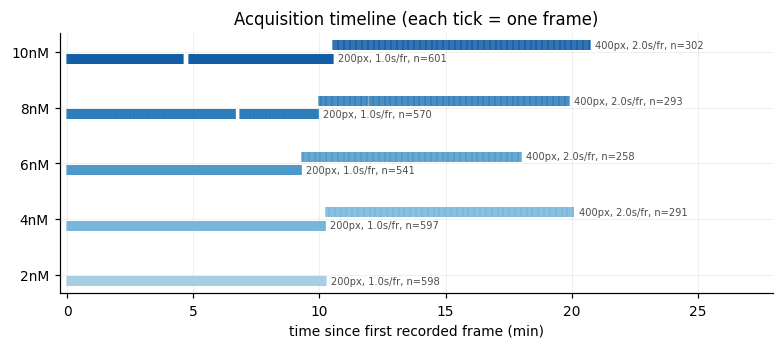

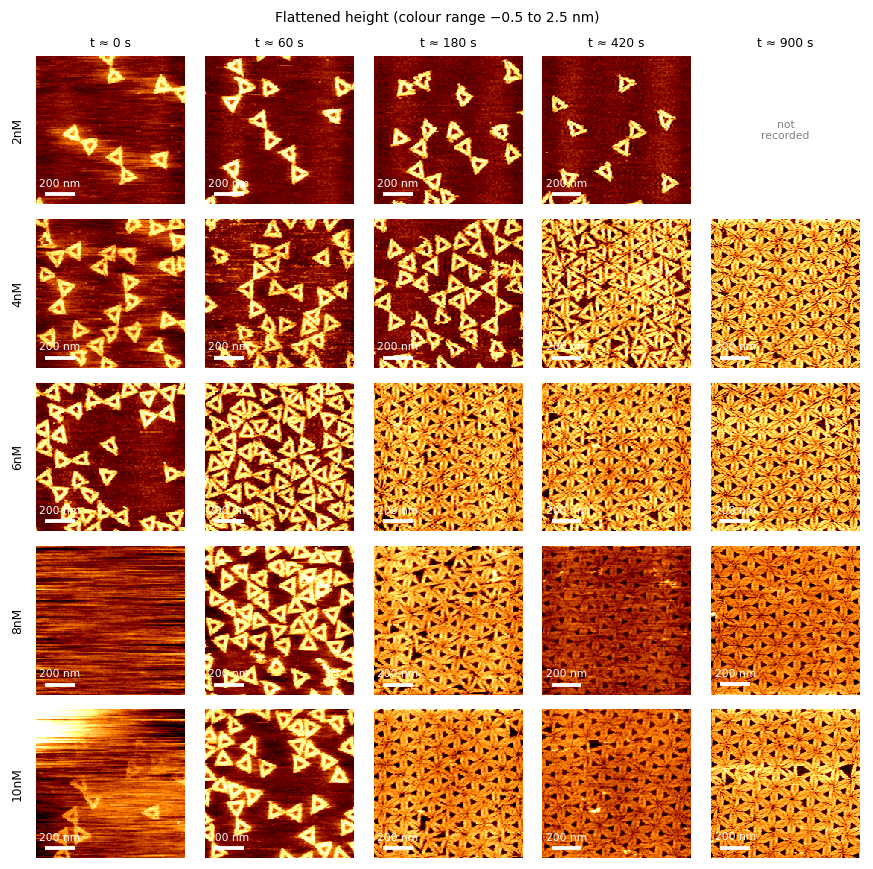

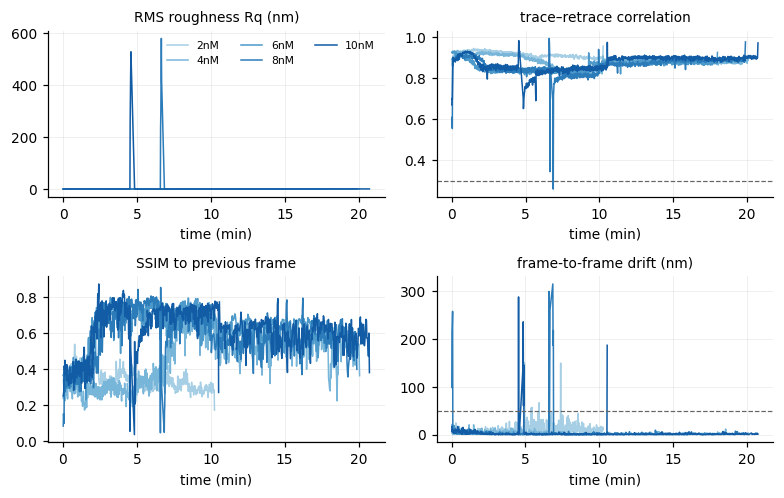

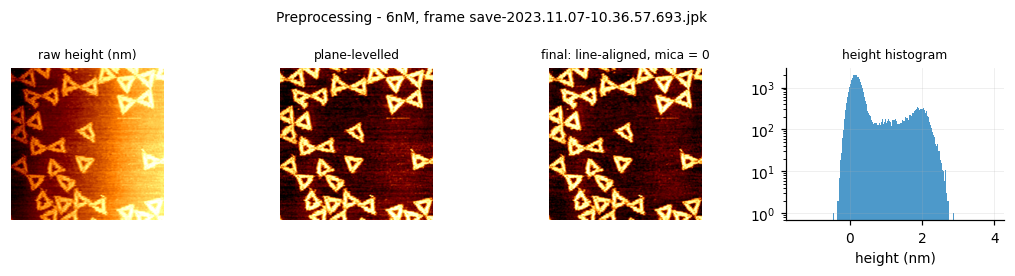

In [13]:
# ---- 12. Figures --------------------------------------------------------------------------
FIG = os.path.join(OUT_DIR, 'figures')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
                     'lines.linewidth': 1.6, 'legend.frameon': False})
# one fixed colour per concentration: single-hue sequential ramp (low conc = light, high = dark)
_ALL = ['2nM', '4nM', '6nM', '8nM', '10nM', '12nM']
_cm = plt.get_cmap('Blues')
CCOL = {c: _cm(0.35 + 0.6 * i / (len(_ALL) - 1)) for i, c in enumerate(_ALL)}

def load_frame(row, retrace=False):
    fn = os.path.join(OUT_DIR, row['stack_file'])
    if retrace:
        fn = fn.replace('_trace.npy', '_retrace.npy')
    return np.load(fn, mmap_mode='r')[int(row['stack_idx'])].astype(np.float32)

def add_scalebar(ax, nm_per_px, nx, length_nm=200):
    px = length_nm / nm_per_px
    ax.plot([nx * 0.06, nx * 0.06 + px], [nx * 0.93] * 2, color='white', lw=2.5, solid_capstyle='butt')
    ax.text(nx * 0.06 + px / 2, nx * 0.89, f'{length_nm} nm', color='white', ha='center', va='bottom', fontsize=7)

# Fig P1-1: acquisition timeline
fig, ax = plt.subplots(figsize=(7.2, 0.45 * len(CONCS) + 1.0))
for yi, c in enumerate(CONCS):
    for _, s in sessions[sessions.conc == c].iterrows():
        g = frames[frames.session == s.session]
        ax.plot(g.t_rel_s / 60, np.full(len(g), yi) + (0.12 if s.nx > 300 else -0.12), '|',
                color=CCOL.get(c, 'k'), ms=7, alpha=0.8)
        ax.text(s.t_end_rel_s / 60 + 0.2, yi + (0.12 if s.nx > 300 else -0.12),
                f'{s.nx}px, {s.frame_dt_s:.1f}s/fr, n={s.n_frames}', va='center', fontsize=6.5, color='0.3')
ax.set_yticks(range(len(CONCS))); ax.set_yticklabels(CONCS)
ax.set_xlabel('time since first recorded frame (min)'); ax.set_title('Acquisition timeline (each tick = one frame)')
ax.set_xlim(left=-0.3, right=frames.t_rel_s.max() / 60 * 1.35)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP1_1_timeline.png')); plt.show()

# Fig P1-2: example frames at matched times (rows = concentration)
T_SHOW = [0, 60, 180, 420, 900]
fig, axes = plt.subplots(len(CONCS), len(T_SHOW), figsize=(1.6 * len(T_SHOW), 1.6 * len(CONCS)), squeeze=False)
for r, c in enumerate(CONCS):
    g = kept[kept.conc == c]
    for k, tt in enumerate(T_SHOW):
        ax = axes[r, k]; ax.axis('off')
        if tt > g.t_rel_s.max() + 5:
            ax.text(0.5, 0.5, 'not\nrecorded', ha='center', va='center', fontsize=7, color='0.5', transform=ax.transAxes)
        else:
            row = g.iloc[(g.t_rel_s - tt).abs().argmin()]
            im = load_frame(row)
            ax.imshow(im, cmap='afmhot', vmin=-0.5, vmax=2.5, interpolation='nearest')
            add_scalebar(ax, row.nm_per_px, row.nx)
        if r == 0: ax.set_title(f't ≈ {tt} s', fontsize=8)
        if k == 0: ax.text(-0.08, 0.5, c, transform=ax.transAxes, rotation=90, va='center', ha='right', fontsize=8)
fig.suptitle('Flattened height (colour range −0.5 to 2.5 nm)', fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP1_2_example_frames.png')); plt.show()

# Fig P1-3: QC traces
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6))
for c in CONCS:
    g = frames[frames.conc == c]
    kw = dict(color=CCOL.get(c, 'k'), label=c, lw=1.0)
    axes[0, 0].plot(g.t_rel_s / 60, g.rq_nm, **kw)
    axes[0, 1].plot(g.t_rel_s / 60, g.tr_corr, **kw)
    axes[1, 0].plot(g.t_rel_s / 60, g.ssim_prev, **kw)
    axes[1, 1].plot(g.t_rel_s / 60, np.hypot(g.drift_dx_nm, g.drift_dy_nm), **kw)
for ax, t in zip(axes.ravel(), ['RMS roughness Rq (nm)', 'trace–retrace correlation',
                                 'SSIM to previous frame', 'frame-to-frame drift (nm)']):
    ax.set_title(t, fontsize=9); ax.set_xlabel('time (min)')
axes[0, 1].axhline(TR_CORR_MIN, color='0.4', ls='--', lw=0.8)
axes[1, 1].axhline(DRIFT_JUMP_NM, color='0.4', ls='--', lw=0.8)
axes[0, 0].legend(ncol=3, fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP1_3_qc_traces.png')); plt.show()

# Fig P1-4: preprocessing demonstration (re-read one raw frame from the first available zip)
demo_c = CONCS[len(CONCS) // 2]
demo_row = kept[kept.conc == demo_c].iloc[0]
with zipfile.ZipFile(os.path.join(DATA_DIR, available[demo_c])) as zf:
    raw_m = read_jpk_height(zf.read(demo_row.member), demo_row.member, want_retrace=False)['trace']
steps = [('raw height (nm)', raw_m * 1e9 - np.median(raw_m * 1e9)),
         ('plane-levelled', plane_level(raw_m * 1e9)),
         ('final: line-aligned, mica = 0', flatten_nm(raw_m, nm_per_px=demo_row.nm_per_px))]
fig, axes = plt.subplots(1, 4, figsize=(9.6, 2.5))
for ax, (t, im) in zip(axes[:3], steps):
    lo_, hi_ = np.percentile(im, [1, 99.5]); ax.imshow(im, cmap='afmhot', vmin=lo_, vmax=hi_); ax.set_title(t, fontsize=8); ax.axis('off')
fin = steps[-1][1]
axes[3].hist(fin.ravel(), bins=200, range=(-1.5, 4), color=CCOL.get(demo_c, 'C0'))
axes[3].set_yscale('log'); axes[3].set_xlabel('height (nm)'); axes[3].set_title('height histogram', fontsize=8)
fig.suptitle(f'Preprocessing - {demo_c}, frame {demo_row.member.split("/")[-1]}', fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP1_4_preprocessing.png')); plt.show()

In [14]:
# ---- 13. Gate table ------------------------------------------------------------------------
gates = []
md5s = [r.get('md5_ok') for r in RUN_INFO if 'failed' not in r]
gates.append(('All zips match Zenodo MD5', all(m in (True, None) for m in md5s),
              ', '.join(f"{r['conc']}:{r.get('md5_ok')}" for r in RUN_INFO if 'failed' not in r)))
gates.append(('Every available zip processed', all('failed' not in r for r in RUN_INFO), f'{len(CONCS)}/{len(available)}'))
px_const = sessions.groupby('session').nm_per_px.nunique().eq(1).all()
gates.append(('Single pixel size per session', bool(px_const), str([float(x) for x in sorted(sessions.nm_per_px.round(3).unique())])))
exc = frames.exclude.astype(bool).mean()
gates.append(('Excluded frames < 5 %', bool(exc < 0.05), f'{100*exc:.2f} %'))
gates.append(('No frame/pixel leakage in movie-level splits',
              bool((audit[['frame_overlap', 'concentration_overlap', 'identical_pixel_frames']].values == 0).all()), ''))
gates.append(('Temporal split blocks disjoint', bool(tmp_ok), f'gap = {TEMPORAL_GAP} frames'))
gates.append(('Normalisation stats per session only', True, 'sessions.csv: norm_median_nm / norm_iqr_nm'))
gates.append(('All 6 concentrations present', len(CONCS) == 6, f'missing: {missing}' if missing else 'ok'))
G = pd.DataFrame(gates, columns=['gate', 'pass', 'detail'])
G['pass'] = G['pass'].map({True: 'PASS', False: 'FAIL'})
display(G)
G.to_csv(os.path.join(OUT_DIR, 'gates_portion1.csv'), index=False)
json.dump({'created': datetime.now().isoformat(timespec='seconds'), 'python': platform.python_version(),
           'numpy': np.__version__, 'tifffile': tifffile.__version__, 'skimage': skimage.__version__,
           'config': {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, tuple, dict, bool))}},
          open(os.path.join(OUT_DIR, 'run_config_portion1.json'), 'w'), indent=1, default=str)
print('Outputs written to', OUT_DIR)
for f in sorted(glob.glob(os.path.join(OUT_DIR, '*'))):
    print('  ', os.path.basename(f))

,gate,pass,detail
0,All zips match Zenodo MD5,PASS,"2nM:True, 4nM:True, 6nM:True, 8nM:True, 10nM:True"
1,Every available zip processed,PASS,5/5
2,Single pixel size per session,PASS,"[2.5, 5.0]"
3,Excluded frames < 5 %,PASS,0.37 %
4,No frame/pixel leakage in movie-level splits,PASS,
5,Temporal split blocks disjoint,PASS,gap = 16 frames
6,Normalisation stats per session only,PASS,sessions.csv: norm_median_nm / norm_iqr_nm
7,All 6 concentrations present,FAIL,missing: ['12nM']


Outputs written to /content/drive/MyDrive/Koushik-experiment/portion1_outputs
   figures
   frames_all.csv
   gates_portion1.csv
   leakage_audit.csv
   processed
   qc_summary.csv
   run_config_portion1.json
   sessions.csv
   splits.json


## What you have now (`portion1_outputs/`)
| File | Content |
|---|---|
| `processed/<conc>/<session>_trace.npy` (+`_retrace.npy`) | float16 stacks, flattened height in **nm**, shape (frames, ny, nx) |
| `frames_all.csv` | one row per frame: time (`t_rel_s`), session, pixel size, all QC values and flags, `exclude`, `stack_file`/`stack_idx` |
| `sessions.csv` | per imaging session: resolution, nm/px, frame interval, duration, per-session normalisation stats |
| `splits.json` | LOCO (primary), P1 / P1r hold-outs, within-session temporal split with gaps |
| `qc_summary.csv`, `leakage_audit.csv`, `gates_portion1.csv` | audit tables for the paper's Methods / Supplement |
| `figures/figP1_*.png` | timeline, example frames, QC traces, preprocessing demo (300 dpi) |

**Before Portion 2:** all gates should be PASS (the "all 6 concentrations" gate passes once every zip is uploaded — just re-run; finished zips are skipped).
An MD5 **mismatch** means the zip on Drive is incomplete/corrupt: re-download that zip from Zenodo, delete `processed/<conc>/`, and re-run.